# 05 · Equity vs. bond: do the stock and the bonds agree?

**The question:** stock and bond investors are looking at the same company. Do they see the same default risk? Where they disagree, one of them is wrong, or they own different things.

**Short answer** (stock prices Nov 10, 2026; bonds: TRACE last trades the same day):
1. **Big tech: the bond spread isn't about default.** The stocks imply ~0bp of default spread for Apple, Alphabet and Meta, against the 31, 69 and 93bp their ~5-year bonds pay (§3, `05_equity_vs_bond.png`).
2. **Beignet isn't priced on Meta's credit.** Its 23% implied 5-year odds are ~330× what Meta's stock implies for Meta (§3).
3. **Beignet's record lows were mostly interest rates.** Of its ~8-point fall since issue, all of it is Treasury yields rising; credit or structure accounts for ~0 (§5, `05_meta_vs_beignet.png`).
4. **SpaceX and CoreWeave: revised in 06 §7.** With realised volatility (this notebook), SpaceX's stock implies ~77bp and CoreWeave's ~1,555bp, more pessimistic than its bonds. With *option-implied* volatility (06 §7), SpaceX's falls to ~1bp, and CoreWeave's to ~1,136bp, within ~100bp of its bond (~1,041bp). The realised-volatility results below are kept as a record, but **06 §7 supersedes them.**

**The idea (Merton, 1974).** Shareholders are paid *last*. If the company's assets are worth more than its debt when the debt comes due, shareholders keep the difference. If not, they get zero and the lenders take the company. So a share works like a **call option on the company's assets**, with the debt as the strike price.

That lets us run the logic backwards. The stock price and how much it swings tell us:
1. **V**: what the whole company (assets) is worth.
2. **σ_V**: how much that value swings.
3. **Distance to default**: how many "standard swings" V sits above the debt. Far away means a safe company. Close means the debt could end up worth more than the assets.

From those comes an **equity-implied default probability**, which we set next to the bond-implied odds from notebook 03.

**How this notebook gets there:**

| § | Question | Chart / table |
|---|---|---|
| 1 | What are the inputs: equity value, volatility, debt? | (table) |
| 2 | How does Merton turn those into default odds? | (method) |
| 3 | Stock vs. bonds, side by side: do they agree? | `05_equity_vs_bond.png` |
| 4 | Does the answer survive different inputs? | (table) |
| 5 | Meta stock vs. the Beignet bond: credit, or rates? | `05_meta_vs_beignet.png` |

**Inputs:** `issuers.csv` (shares, debt, cash from the latest 10-Qs, each with a source), stock prices cached by `01_data_pull.ipynb`, and `data/implied_pd.csv` from 03.

**Outputs:** `data/merton_inputs.csv` and `data/equity_vs_bond.csv` (used by 06), plus the two `charts/05_*.png`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
import matplotlib.dates as mdates
from common import (INK, INK2, MUTED, AXIS, SURFACE, BOND, EQUITY, source_note, load_equity,
                    treasury_yield, bond_price, norm_cdf)

CHARTS = Path('charts')
issuers = pd.read_csv('issuers.csv', parse_dates=['shares_asof', 'balance_date']).set_index('issuer')
bonds = pd.read_csv('bonds.csv', parse_dates=['maturity']).set_index('bond_id')
spreads = pd.read_csv('data/spreads.csv', parse_dates=['as_of'])
implied = pd.read_csv('data/implied_pd.csv', parse_dates=['as_of'])
AS_OF = implied.as_of.max()          # the bond quote date, so stock and bonds are compared on the same day
px = {i: load_equity(t) for i, t in issuers.ticker.items()}
pd.options.display.float_format = '{:,.2f}'.format
print(f'As of {AS_OF:%b %-d, %Y}')

As of Nov 10, 2026


## 1 · What are the inputs: equity value, volatility, debt?

- **Market cap** = closing price × shares outstanding (all share classes, from the 10-Q cover page). Unlisted classes are valued at the listed price.
- **Equity volatility** = annualised standard deviation of daily returns over the past year. SpaceX listed on June 12, 2026, so it has only ~4 months of history, and its number is shakier. *Option-implied* volatility, the market's forward-looking estimate, would be better. It's done in 06 §7, using Market Data's option chains, and it changes the SpaceX and CoreWeave results. Here we use realised volatility, with a 3-month window as a check.
- **Debt (D)** = face value of borrowings at the last balance sheet. Merton needs one "amount owed." Debt alone ignores other obligations (leases, payables), so section 4 reruns with *total liabilities*.
- **Mismatched dates.** Prices are from Nov 10, but balance sheets are from June or September. (CoreWeave's Sep 30 balance sheet, in its Q3 release, shows $46.9B of debt; `issuers.csv` still has June's $35.55B until the 10-Q is filed.) CoreWeave has borrowed more since June 30, so its debt is, if anything, understated.

In [2]:
def realized_vol(s, days):
    r = np.log(s.adjclose).diff().dropna().loc[:AS_OF].tail(days)
    return r.std() * np.sqrt(252), len(r)

rows = {}
for iss, f in issuers.iterrows():
    p = px[iss].loc[:AS_OF]
    v1, n1 = realized_vol(px[iss], 252)
    v3, _ = realized_vol(px[iss], 63)
    rows[iss] = {'price': p.close.iloc[-1], 'price date': p.index[-1].date(), 'market cap ($bn)': p.close.iloc[-1] * f.shares_mn / 1e3,
                 'debt ($bn)': f.debt_face_bn, 'total liabilities ($bn)': f.total_liabilities_bn, 'cash ($bn)': f.cash_securities_bn,
                 'vol 1y': v1, 'days used': n1, 'vol 3m': v3}
inp = pd.DataFrame(rows).T
inp['debt / market cap'] = inp['debt ($bn)'] / inp['market cap ($bn)']
inp.rename_axis('issuer').to_csv('data/merton_inputs.csv')   # handoff to 06
inp

,price,price date,market cap ($bn),debt ($bn),total liabilities ($bn),cash ($bn),vol 1y,days used,vol 3m,debt / market cap
Apple,348.51,2026-11-10,"5,086.22",84.34,275.75,146.52,0.25,252,0.22,0.02
Alphabet,287.38,2026-11-10,"3,514.66",101.08,281.50,242.47,0.34,252,0.35,0.03
Meta,641.39,2026-11-10,"1,639.55",84.00,206.45,82.45,0.41,252,0.45,0.05
SpaceX,143.09,2026-11-10,"1,943.31",38.01,77.28,89.90,0.82,104,0.58,0.02
CoreWeave,48.73,2026-11-10,26.88,35.55,72.05,5.54,0.97,252,0.87,1.32


## 2 · How does Merton turn those into default odds?

Shareholders own a call option on assets V, with strike D, expiring in T years. The Black–Scholes formula gives its value:

$$E = V\,N(d_1) - D e^{-rT} N(d_2), \qquad d_1 = \frac{\ln(V/D) + (r + \sigma_V^2/2)T}{\sigma_V\sqrt{T}}, \quad d_2 = d_1 - \sigma_V\sqrt{T}$$

Here N(·) is the bell-curve probability function. Equity swings more than assets because of leverage, and the link is:

$$\sigma_E\,E = N(d_1)\,\sigma_V\,V$$

We know E and σ_E from the stock market, and D, r, T as inputs. That leaves two equations and two unknowns (V, σ_V). We solve them by repetition: guess σ_V, find the V that reprices the stock, update σ_V from the second equation, and repeat until nothing changes.

**Outputs:**
- **Distance to default** = d₂: how many standard deviations V sits above D at the horizon.
- **Default probability** = N(−d₂): the chance V ends below D.
- **Merton spread**: the yield over Treasuries a lender *should* charge, given that default chance and the recovery implied by the model (whatever V is left):

$$s = -\frac{1}{T}\ln\left(N(d_2) + \frac{V}{D e^{-rT}} N(-d_1)\right)$$

Like the bond-implied odds in 03, these are **risk-neutral** odds, so the two are like-for-like. The spread is especially useful because it's in the same units as the bond spread, with no recovery assumption needed.

**Horizon:** T = 5 years, matching the 5-year window in 03. Classic Merton only checks for default at T. A company that runs out of cash in year 2 but would have recovered by year 5 doesn't count. That's a real limitation for SpaceX's burn story (see 03 §6 and 06 §5).

**Next:** run it for each issuer and set it next to the bond. §3.

In [3]:
from common import merton   # solver + self-checks live in common.py

T = 5
r = np.log(1 + treasury_yield(AS_OF, T) / 100)   # continuously compounded 5y Treasury
eq = pd.DataFrame({iss: merton(row['market cap ($bn)'], row['vol 1y'], row['debt ($bn)'], r, T) for iss, row in inp.iterrows()}).T
eq.style.format({'V': '${:,.0f}bn', 'sig_V': '{:.0%}', 'DD': '{:.1f}', 'pd': '{:.4%}', 'spread_bp': '{:.1f}bp'})

,V,sig_V,DD,pd,spread_bp
Apple,"$5,153bn",25%,7.6,0.0000%,0.0bp
Alphabet,"$3,595bn",33%,4.8,0.0001%,0.0bp
Meta,"$1,706bn",40%,3.2,0.0681%,0.3bp
SpaceX,"$1,972bn",81%,1.4,8.0593%,76.7bp
CoreWeave,$40bn,77%,-0.7,74.4854%,1555.3bp


## 3 · Stock vs. bonds, side by side: do they agree?

For each issuer we take the bond **closest to 5 years** to maturity, to match the horizon. We compare:
- **Spread**: the actual bond spread vs. the Merton spread implied by the stock. The difference is what bond investors charge that the stock market doesn't see as default risk. That covers liquidity and risk premia, *and* any disagreement about the company.
- **5-year default odds**: the credit-triangle odds (03) vs. Merton's N(−d₂).

Meta gets a second row for **Beignet**. The stock is still Meta's: if Beignet's only risk were Meta not paying, the stock says how big that risk is. Beignet is ~22 years, not 5, so read its row loosely.

In [4]:
near5 = (implied.assign(gap=(implied.years - T).abs()).sort_values('gap').groupby('issuer').head(1).set_index('issuer'))
cmp_rows = []
for iss in ['Apple', 'Alphabet', 'Meta', 'Meta (SPV)', 'SpaceX', 'CoreWeave']:
    stock = 'Meta' if iss == 'Meta (SPV)' else iss
    b = implied[implied.bond_id == 'BEIGNET_6.581_2049'].iloc[0] if iss == 'Meta (SPV)' else near5.loc[iss]
    cmp_rows.append({'issuer': iss, 'bond': b.bond_id, 'years': b.years, 'bond spread': b.g_spread, 'stock-implied spread': eq.loc[stock, 'spread_bp'],
                     'bond 5y odds': b.pd_5y, 'stock 5y odds': eq.loc[stock, 'pd'], 'distance to default': eq.loc[stock, 'DD']})
cmp = pd.DataFrame(cmp_rows).set_index('issuer')
cmp['unexplained spread'] = cmp['bond spread'] - cmp['stock-implied spread']
cmp.to_csv('data/equity_vs_bond.csv')   # used by 06
cmp.style.format({'years': '{:.1f}', 'bond spread': '{:.0f}bp', 'stock-implied spread': '{:.1f}bp', 'unexplained spread': '{:.0f}bp',
                  'bond 5y odds': '{:.1%}', 'stock 5y odds': '{:.3%}', 'distance to default': '{:.1f}'})

,bond,years,bond spread,stock-implied spread,bond 5y odds,stock 5y odds,distance to default,unexplained spread
issuer,,,,,,,,
Apple,AAPL_4.20_2030,3.5,31bp,0.0bp,2.6%,0.000%,7.6,31bp
Alphabet,GOOG_4.100_2031,4.3,69bp,0.0bp,5.6%,0.000%,4.8,69bp
Meta,META_4.55_2031,4.5,93bp,0.3bp,7.5%,0.068%,3.2,92bp
Meta (SPV),BEIGNET_6.581_2049,22.6,201bp,0.3bp,22.7%,0.068%,3.2,200bp
SpaceX,SPCX_5.350_2031,4.7,255bp,76.7bp,19.5%,8.059%,1.4,178bp
CoreWeave,CRWV_9.75_2031,4.9,1041bp,1555.3bp,61.4%,74.485%,-0.7,-514bp


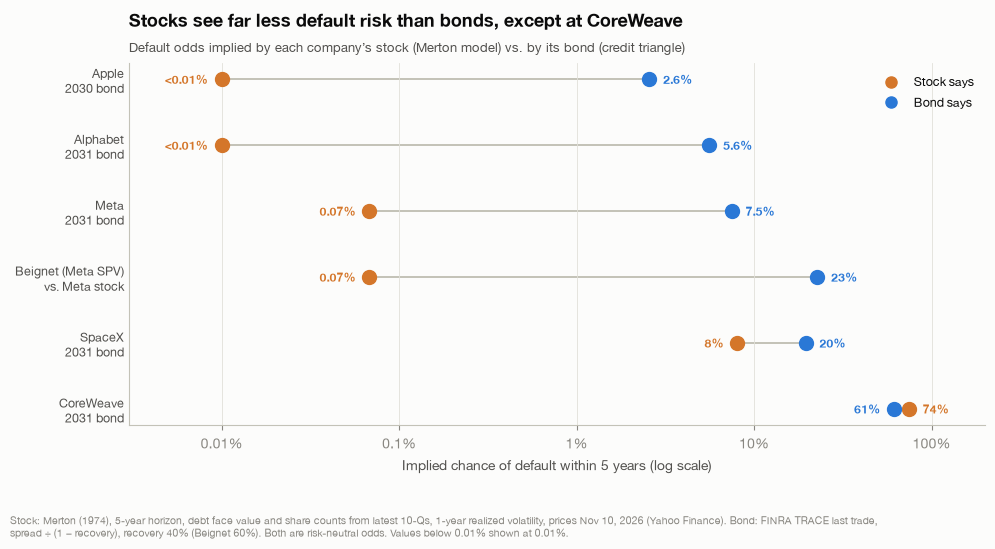

In [5]:
FLOOR = 1e-4   # show anything below 0.01% at the floor
fig, ax = plt.subplots(figsize=(10, 5.2))
for y, (iss, r_) in enumerate(cmp.iterrows()):
    s, b = max(r_['stock 5y odds'], FLOOR), r_['bond 5y odds']
    ax.plot([s, b], [y, y], color=AXIS, lw=1.4, zorder=1)
    ax.plot(s, y, 'o', ms=10, color=EQUITY, zorder=3)
    ax.plot(b, y, 'o', ms=10, color=BOND, zorder=3)
    s_txt = '<0.01%' if r_['stock 5y odds'] < FLOOR else f"{r_['stock 5y odds']:.2%}" if r_['stock 5y odds'] < 0.01 else f"{r_['stock 5y odds']:.0%}"
    b_txt = f"{b:.0%}" if b >= 0.1 else f'{b:.1%}'
    sl, bl = (-10, 10) if s <= b else (10, -10)          # outer label on each side, so they never collide
    ax.annotate(s_txt, (s, y), xytext=(sl, 0), textcoords='offset points', ha='right' if sl < 0 else 'left', va='center',
                fontsize=8.5, color=EQUITY, fontweight='bold')
    ax.annotate(b_txt, (b, y), xytext=(bl, 0), textcoords='offset points', ha='left' if bl > 0 else 'right', va='center',
                fontsize=8.5, color=BOND, fontweight='bold')
labels = [f'{i}\n{bonds.loc[r_.bond, "maturity"]:%Y} bond' if i != 'Meta (SPV)' else 'Beignet (Meta SPV)\nvs. Meta stock'
          for i, r_ in cmp.iterrows()]
ax.set_yticks(range(len(cmp)), labels, fontsize=9)
ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
ax.set_xscale('log'); ax.set_xlim(3e-5, 2)
ax.xaxis.set_major_locator(mticker.FixedLocator([1e-4, 1e-3, 1e-2, 1e-1, 1]))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.2%}' if v < 1e-3 else f'{v:.1%}' if v < 1e-2 else f'{v:.0%}'))
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.set_xlabel('Implied chance of default within 5 years (log scale)')
ax.set_title('Stocks see far less default risk than bonds, except at CoreWeave', pad=26)
ax.text(0, 1.03, 'Default odds implied by each company’s stock (Merton model) vs. by its bond (credit triangle)', transform=ax.transAxes, fontsize=9.5, color=INK2)
ax.legend(handles=[Line2D([], [], marker='o', ls='', ms=8, color=EQUITY, label='Stock says'),
                   Line2D([], [], marker='o', ls='', ms=8, color=BOND, label='Bond says')], loc='upper right', fontsize=9)
source_note(fig, f'Stock: Merton (1974), {T}-year horizon, debt face value and share counts from latest 10-Qs, 1-year realized volatility, prices {AS_OF:%b %-d, %Y} (Yahoo Finance).\n'
                 'Bond: FINRA TRACE last trade, spread ÷ (1 − recovery), recovery 40% (Beignet 60%). Both are risk-neutral odds. Values below 0.01% shown at 0.01%.')
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(CHARTS / '05_equity_vs_bond.png', dpi=200)
plt.show()

**What this shows** (`charts/05_equity_vs_bond.png`, above):

**Big tech: the bond spread isn't about default.** The stock-implied spreads are 0.0bp (Apple), 0.0bp (Alphabet), and 0.3bp (Meta), against 31, 69, and 93bp paid on the ~5-year bonds. Even with total liabilities and the jumpier 3-month volatility, Meta tops out at ~7bp. So nearly all of an AA bond's spread pays for something other than default: liquidity, duration, and the sheer *supply* of new hyperscaler bonds that buyers must absorb. **That's why Meta's spread widening since April (02 §5) is a supply and sentiment story, not a solvency one, at least as far as the stock is concerned.**

**Beignet: the stock says Meta is fine, the bond is priced like junk-adjacent risk.** Beignet's 23% implied 5-year odds sit about 330× above what Meta's stock implies for Meta. Either the market sees risks in Beignet that Meta's own investors don't bear (lease non-renewal after year 4, a residual value guarantee that may not trigger, an asset nobody else wants), or Beignet is simply cheap. That's the core question of the post, and the stock market answers half of it: **it isn't Meta's credit that's being priced.**

**SpaceX: the stock implies less risk than the bonds, but the number is fragile.** The stock implies ~77bp (range 2–152bp across inputs) vs. ~255bp paid. It rests on ~104 trading days of very volatile post-IPO stock (58–82%). With a $2T market cap and $38B of debt, SpaceX's assets would have to fall ~98% for the debt to be at risk. Merton only gets non-trivial odds because the volatility is so high. Either way, **bond investors charge at least ~100bp more than the stock implies**, consistent with 03 §6: the bond spread is pricing something other than near-term balance-sheet default (downgrade, priming by secured GPU debt, the burn trajectory, 144A illiquidity). *(Revised in 06 §7: with option-implied volatility of 55% instead of 82%, the stock-implied spread falls to ~1bp. The gap to the bond is bigger, not smaller.)*

**CoreWeave: the stock is *more* worried than the bonds.** The stock implies a 1,555bp spread (74% 5-year odds) vs. 1,041bp paid. That holds under every input combination (1,130–1,739bp), and CoreWeave's debt is if anything understated (June balance sheet, before the September convert). The unsecured notes are also *junior* to ~$25B of secured debt, so they should pay *more* than Merton's average-debt spread, not less. **By the stock's reckoning, CoreWeave's unsecured bondholders are underpaid.** Possible explanations:
- The stock's 97% volatility includes speculative swings that aren't about solvency.
- Bond investors expect help from a strategic backer (Nvidia, a customer) or a better-than-modelled recovery.
- The bond market is slower to reprice.

*(Revised in 06 §7: with option-implied volatility of 87% instead of 97%, CoreWeave's stock-implied spread is ~1,136bp against ~1,041bp on the bond. Once volatility is forward-looking, the stock and the bonds roughly agree. The large "underpaid" gap above was mostly a realised-volatility artifact.)*

**Next:** are these results artifacts of the inputs? §4 varies them.

## 4 · Does the answer survive different inputs?

Merton is sensitive to two choices: **what counts as debt** and **which volatility to use**. Below, the stock-implied 5-year default odds and spread for each combination. If the gap to the bond market survives every row, it isn't an artefact of the inputs.

In [6]:
sens = []
for iss, row in inp.iterrows():
    for d_lbl, D in [('debt', row['debt ($bn)']), ('total liabilities', row['total liabilities ($bn)'])]:
        for v_lbl in ['vol 1y', 'vol 3m']:
            m = merton(row['market cap ($bn)'], row[v_lbl], D, r, T)
            sens.append({'issuer': iss, 'D': d_lbl, 'vol': f'{v_lbl} ({row[v_lbl]:.0%})', '5y odds': m['pd'], 'spread': m['spread_bp']})
sens = pd.DataFrame(sens).set_index(['issuer', 'D', 'vol'])
sens.style.format({'5y odds': '{:.3%}', 'spread': '{:.1f}bp'})

**What this shows:**
- **Apple, Alphabet, Meta** stay near zero under every combination; Meta tops out at ~7bp with total liabilities and 3-month volatility. The big-tech conclusion is robust.
- **SpaceX** ranges ~2–152bp depending on the volatility window: fragile, because it rests on ~104 days of post-IPO trading.
- **CoreWeave** ranges ~1,130–1,739bp. That looks robust here, but every row uses *realised* volatility, which is exactly the input 06 §7 replaces.

**Next:** Beignet's row in §3 says its price isn't about Meta's credit. So what moved it? §5 splits its fall into rates and credit.

## 5 · Meta stock vs. the Beignet bond: credit, or rates?

Three lines since Beignet was sold at par on Oct 16, 2025 (all indexed to 100 then):
- **Meta stock** (orange).
- **Beignet, rates only** (gray, dashed): what Beignet would be worth if its spread had stayed at the issue level and only Treasury yields had moved. Bond prices fall when rates rise, regardless of credit.
- **Beignet, actual trades** (blue dots), from `quotes.csv`.

The gap between the gray line and the blue dots is the part of Beignet's fall that's about *credit*: the market charging more for the structure.

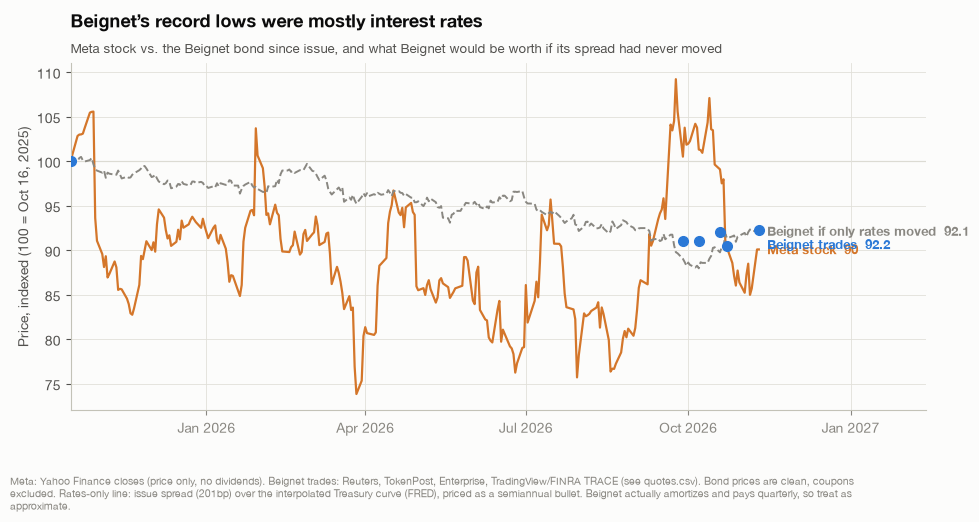

Meta stock: -10%.  Beignet: -7.8 pts, of which rates -7.9, credit/structure +0.1.


In [7]:
BID = 'BEIGNET_6.581_2049'
bb = bonds.loc[BID]
issue = spreads[(spreads.bond_id == BID) & (spreads.kind == 'issue')].iloc[0]
start = issue.as_of
dates = pd.bdate_range(start, AS_OF)
rates_only = pd.Series([bond_price(treasury_yield(d, (bb.maturity - d).days / 365.25) + issue.g_spread / 100, bb.coupon,
                                   (bb.maturity - d).days / 365.25) for d in dates], index=dates)
meta = px['Meta'].close.loc[start:AS_OF]
meta = meta / meta.iloc[0] * 100
trades = spreads[(spreads.bond_id == BID) & (spreads.kind == 'trade')].set_index('as_of').price.sort_index()

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(meta.index, meta, color=EQUITY, lw=1.6)
ax.plot(rates_only.index, rates_only, color=MUTED, lw=1.4, ls='--')
ax.plot([start] + list(trades.index), [100] + list(trades.values), 'o', color=BOND, ms=7, zorder=3)
ax.axhline(100, color=AXIS, lw=0.8, zorder=0)
for s, txt, c in [(meta, f'Meta stock  {meta.iloc[-1]:.0f}', EQUITY), (rates_only, f'Beignet if only rates moved  {rates_only.iloc[-1]:.1f}', MUTED)]:
    ax.annotate(txt, (s.index[-1], s.iloc[-1]), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9, color=c, fontweight='bold')
ax.annotate(f'Beignet trades  {trades.iloc[-1]:.1f}', (trades.index[-1], trades.iloc[-1]), xytext=(6, -10), textcoords='offset points',
            va='center', fontsize=9, color=BOND, fontweight='bold')
ax.set_xlim(start, AS_OF + pd.Timedelta(days=95))
ax.xaxis.set_major_locator(mdates.MonthLocator((1, 4, 7, 10)))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}'))
ax.set_ylabel('Price, indexed (100 = Oct 16, 2025)')
ax.set_title('Beignet’s record lows were mostly interest rates', pad=26)
ax.text(0, 1.03, 'Meta stock vs. the Beignet bond since issue, and what Beignet would be worth if its spread had never moved', transform=ax.transAxes, fontsize=9.5, color=INK2)
source_note(fig, 'Meta: Yahoo Finance closes (price only, no dividends). Beignet trades: Reuters, TokenPost, Enterprise, TradingView/FINRA TRACE (see quotes.csv). Bond prices are clean, coupons excluded.\n'
                 'Rates-only line: issue spread (201bp) over the interpolated Treasury curve (FRED), priced as a semiannual bullet. Beignet actually amortizes and pays quarterly, so treat as approximate.')
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(CHARTS / '05_meta_vs_beignet.png', dpi=200)
plt.show()
print(f'Meta stock: {meta.iloc[-1] - 100:+.0f}%.  Beignet: {trades.iloc[-1] - 100:+.1f} pts, of which rates {rates_only.iloc[-1] - 100:+.1f}, credit/structure {trades.iloc[-1] - rates_only.iloc[-1]:+.1f}.')

**What this shows** (`charts/05_meta_vs_beignet.png`, above):

**Meta stock vs. Beignet.** Since issue, Meta's stock is down ~10% and Beignet ~8 points. **All of Beignet's fall is rates** (the gray line, −7.9 points); credit or structure is ~0 (+0.1). The bond's record lows were mostly the Treasury market, not a verdict on Meta's data centers (07 confirms this with a proper amortizing model). The divergence the press noticed was real but brief: from early September to mid-October, Meta rallied ~25% while Beignet hit record lows around 91. But the gray line fell just as much over those weeks: long Treasury yields rose. So the divergence is mostly stocks vs. rates, not stock vs. structure.

## Findings, by section

- **§3 · Big tech:** the stocks imply ~0bp of default spread. The 31–93bp their bonds pay is liquidity, duration and supply, not default risk. (`05_equity_vs_bond.png`)
- **§3 · Beignet:** 23% implied 5-year odds, ~330× what Meta's stock implies for Meta. Its yield isn't pricing Meta's credit; 07 asks what it *is* pricing.
- **§3–4 · SpaceX and CoreWeave, superseded by 06 §7:**
  - With realised volatility, SpaceX's stock implies ~77bp (2–152bp) and CoreWeave's ~1,555bp (more pessimistic than its bonds).
  - With option-implied volatility, SpaceX's is ~1bp and CoreWeave's ~1,136bp vs. ~1,041bp on its bond.
- **§5 · Beignet's fall since issue is all rates:** ~8 of ~8 points. The September–October divergence from Meta's stock was stocks vs. rates, not stock vs. structure. (`05_meta_vs_beignet.png`)

**Handoff:** `data/merton_inputs.csv` (market cap, debt, volatility) and `data/equity_vs_bond.csv` (bond vs. stock-implied, by issuer), both used by 06.

## Notes and caveats

- **Merton says big tech can't default, and that's roughly right.** Apple, Alphabet and Meta have debt equal to a few percent of their market value. Assets would have to fall ~95% for the debt to be at risk. Their bond spreads are therefore almost entirely *not* about default: they pay for liquidity, duration, and supply (who has to buy all those new bonds). That's the backdrop for every other comparison here.
- **Model limits.**
  - Default is checked only at year 5.
  - Volatility is assumed constant.
  - There's a single debt amount with no maturity schedule.
  - Asset value is assumed to follow a smooth random walk. Real defaults often come as *jumps*: a lost customer, or a refinancing that fails. Merton tends to *understate* short-horizon default odds for exactly the companies where jumps matter (CoreWeave).
- **Realised vs. implied volatility.** Realised volatility looks backward. 06 §7 swaps in option-implied volatility. It's lower for SpaceX (55% vs. 82%) and CoreWeave (87% vs. 97%), and that changes both conclusions (see the short answer).
- **SpaceX's equity history is short** (since Jun 12, 2026), and its post-IPO trading may not reflect a settled view.
- **Meta's debt excludes the SPVs.** Beignet/Sopaipilla debt (~$40B) sits off Meta's balance sheet, and the RVG is a contingent obligation. Adding them to D barely moves Meta's stock-implied odds, because the market cap is so large.